# **EN3160 Image Processing & Computer Vision - Assignment 02**


**Name : Meedeniya M.M.H**  
**Index No. : 230407K**

### **Github Repository** : https://github.com/manjarimeedeniya/EN3160-Assignment-2

sigma range: 2.5 to 9.0, 26 blobs
largest: x=0, y=275, r=10.6, sigma=7.5
largest: x=282, y=338, r=10.6, sigma=7.5
largest: x=179, y=327, r=8.8, sigma=6.2
largest: x=106, y=255, r=8.8, sigma=6.2
largest: x=178, y=262, r=7.3, sigma=5.2


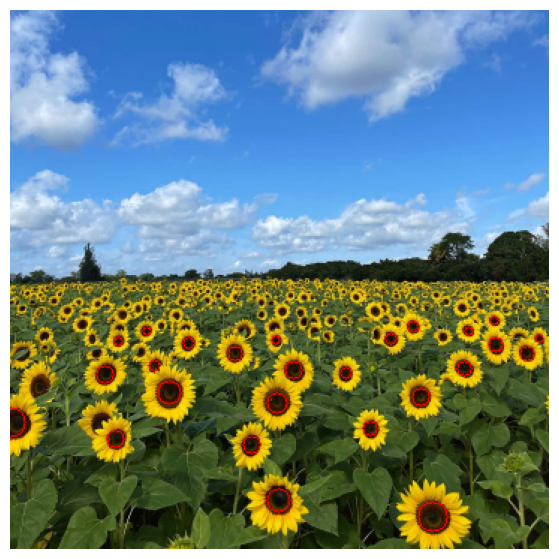

In [57]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

im = cv.imread(r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
g = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255

sigmas = 2.5 * 1.2 ** np.arange(8)     # sigma 2.5 ... ~10.7  -> radius ~3.5 to 15 px
sign = +1                              # dark flower centres
rel_thresh = 0.8                       # relative to the strongest flower-centre response

L = np.stack([sign * s**2 * cv.Laplacian(cv.GaussianBlur(g, (0, 0), s), cv.CV_32F)
              for s in sigmas])

peaks = (L == maximum_filter(L, size=(3, 7, 7))) & (L > rel_thresh * L.max())

k, y, x = np.nonzero(peaks)
r = np.sqrt(2) * sigmas[k]

print(f'sigma range: {sigmas[0]:.1f} to {sigmas[-1]:.1f}, {len(r)} blobs')
for i in np.argsort(-r)[:5]:
    print(f'largest: x={x[i]}, y={y[i]}, r={r[i]:.1f}, sigma={sigmas[k[i]]:.1f}')

out = cv.cvtColor(im, cv.COLOR_BGR2RGB).copy()
for xi, yi, ri in zip(x, y, r):
    cv.circle(out, (int(xi), int(yi)), int(ri), (255, 0, 0), 1)
plt.figure(figsize=(10, 7)); plt.imshow(out); plt.axis('off'); plt.show()

H =
 [[ 2.90e-02  1.00e-03  2.24e+02]
 [-2.10e-01  4.69e-01  1.73e+02]
 [-1.00e-03  0.00e+00  1.00e+00]]


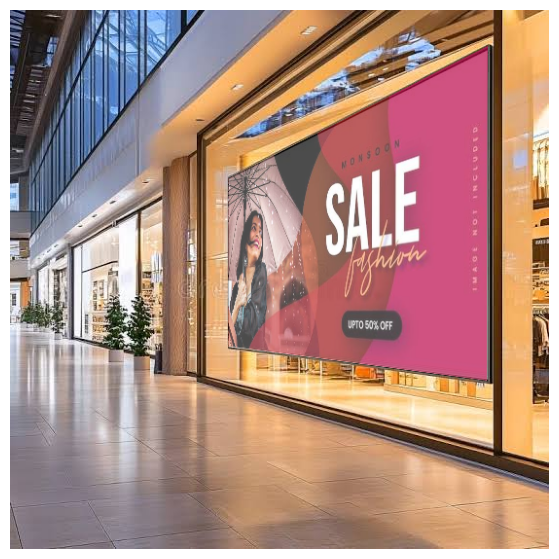

H =
 [[ 5.60e-02 -6.20e-02  1.69e+02]
 [-2.00e-02  1.50e-01  1.19e+02]
 [-0.00e+00 -0.00e+00  1.00e+00]]


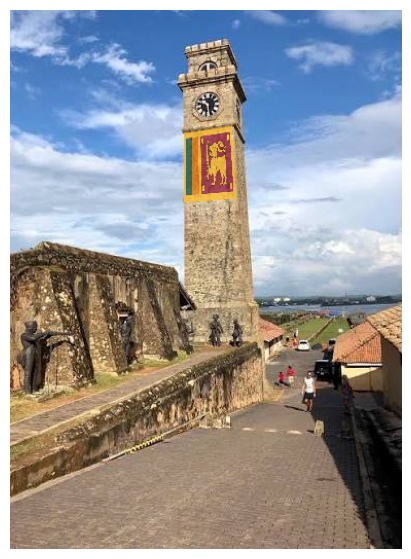

In [ ]:
def pick_points(img, n=4, max_w=1200):
    """Click n points on the image: top-left, top-right, bottom-right, bottom-left."""
    s = min(1.0, max_w / img.shape[1])                 # shrink big images to fit the screen
    show = cv.resize(img, None, fx=s, fy=s)
    pts = []
    def click(event, x, y, flags, param):
        if event == cv.EVENT_LBUTTONDOWN and len(pts) < n:
            pts.append([x / s, y / s])                 # store in original-image coordinates
            cv.circle(show, (x, y), 5, (0, 0, 255), -1)
            cv.imshow('click 4 corners (TL, TR, BR, BL)', show)
    cv.imshow('click 4 corners (TL, TR, BR, BL)', show)
    cv.setMouseCallback('click 4 corners (TL, TR, BR, BL)', click)
    while len(pts) < n:
        cv.waitKey(20)
    cv.waitKey(300); cv.destroyAllWindows()
    return np.float32(pts)

def superimpose(arch, flag, alpha=0.7):
    h, w = flag.shape[:2]
    src = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])   # flag corners
    dst = pick_points(arch)                                              # clicked corners
    H, _ = cv.findHomography(src, dst)                 # flag plane -> building plane
    size = (arch.shape[1], arch.shape[0])
    warped = cv.warpPerspective(flag, H, size)
    mask = cv.warpPerspective(np.ones((h, w), np.float32), H, size)[..., None]
    out = arch * (1 - alpha * mask) + warped * (alpha * mask)
    return H, out.astype(np.uint8)

pairs = [(r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\Empty_Board_2.jfif', r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\advertisment.jfif'),
         (r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\galle face hotel.jfif', r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\Sri_Lanka flag.png')]   # change to your files

for a, f in pairs:
    arch, flag = cv.imread(a), cv.imread(f)
    assert arch is not None and flag is not None, 'check the image paths'
    H, out = superimpose(arch, flag)
    print('H =\n', np.round(H, 3))
    plt.figure(figsize=(10, 7)); plt.imshow(cv.cvtColor(out, cv.COLOR_BGR2RGB)); plt.axis('off'); plt.show()